# Plots

Every explanation of NIFE draws its own plots, with the same API whatever the kind of explanation or the method:

- `explanation.plot()` draws the default plot, and `explanation.plot("tree")` a plot by name. Each kind is also a method: `explanation.plot_tree()`.
- `explanation.plot_kinds()` lists the kinds, with a one-line description.
- Every plot takes an optional matplotlib `ax` and returns the Axes it drew on, so you can place plots in a figure of your own, change them with matplotlib and save them.

The plots share a visual language: **blue** is the instance (what is), **orange** the counterfactual (what would be), and **gray** the context. This notebook explains a random forest that classifies wines. Requirements: `pip install "nife[notebooks]"`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier

from nife.counterfactual import TreeCounterfactualExplainer

X, y = load_wine(return_X_y=True, as_frame=True)
model = RandomForestClassifier(random_state=0).fit(X, y)

explanation = TreeCounterfactualExplainer(model, X, random_state=0).explain(X.iloc[0])
pd.Series(explanation.plot_kinds(), name="description").to_frame()

,description
changes,"What one counterfactual changes: each feature,..."
importances,"The relevant features of the prediction, order..."
tree,"The surrogate tree, compact, with the informat..."


## The plots

| Plot | Shows | Available on | Described in |
|---|---|---|---|
| `changes` (default) | what one counterfactual changes, feature by feature, on the range of each feature in the data | explanations of every counterfactual method | [counterfactual_explanations.ipynb](counterfactual/counterfactual_explanations.ipynb) |
| `importances` | the relevant features, ordered by their importance in the surrogate tree | `TreeCounterfactualExplanation` | [TreeCounterfactualExplainer.ipynb](counterfactual/TreeCounterfactualExplainer.ipynb) |
| `tree` | the surrogate tree, with the instance's decision path and the other side of the counterfactual rule | `TreeCounterfactualExplanation` | [TreeCounterfactualExplainer.ipynb](counterfactual/TreeCounterfactualExplainer.ipynb) |

**`changes`**, the default plot:

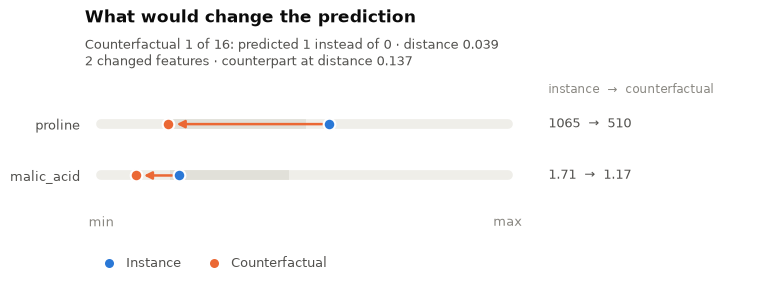

In [2]:
explanation.plot();

**`importances`**:

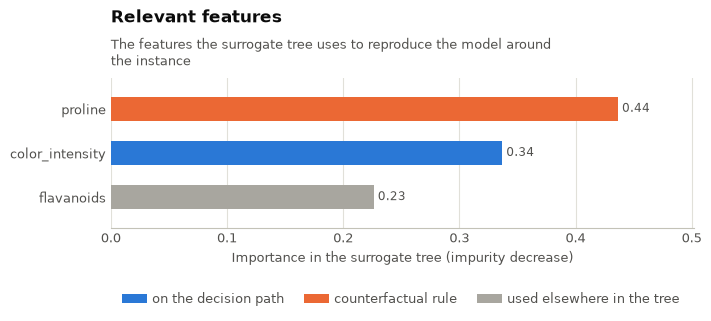

In [3]:
explanation.plot("importances");

**`tree`**:

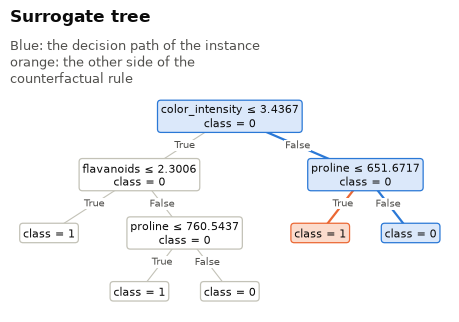

In [4]:
explanation.plot("tree");

## Figures of your own

Plots draw on any matplotlib Axes. Combine them in one figure, change them with matplotlib, and save the figure in any format matplotlib writes, such as PDF or SVG for papers, with `fig.savefig("explanation.pdf")`:

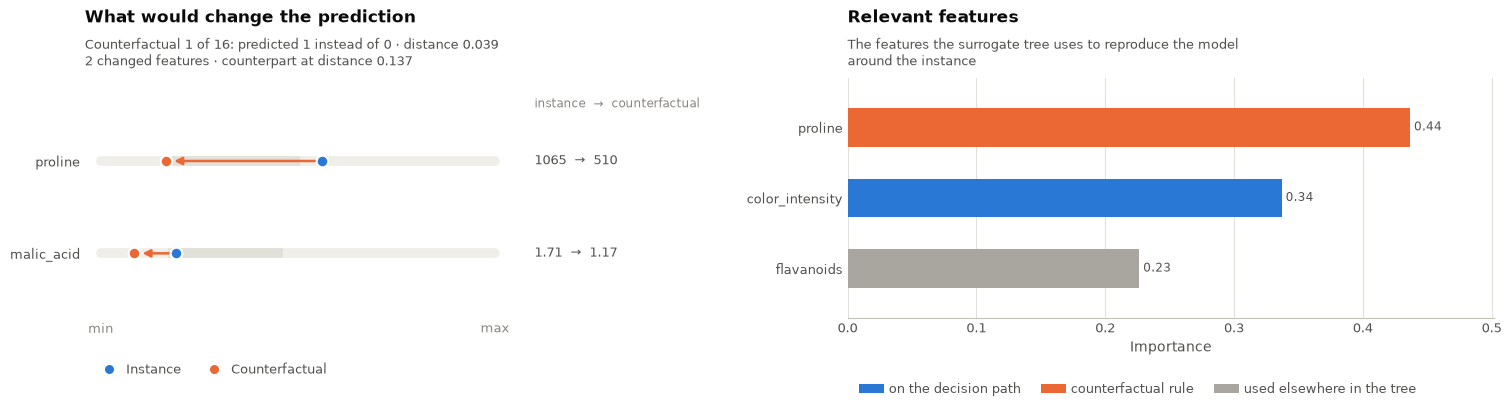

In [5]:
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4), layout="constrained")
explanation.plot_changes(ax=left)
explanation.plot_importances(ax=right)
right.set_xlabel("Importance");  # any matplotlib change

## Colors

The colors are in `nife.plotting.COLORS`, by role. Changing one changes it in every plot. The blue and the orange are the first two hues of a palette validated for color-vision deficiencies; text never takes the color of the marks.

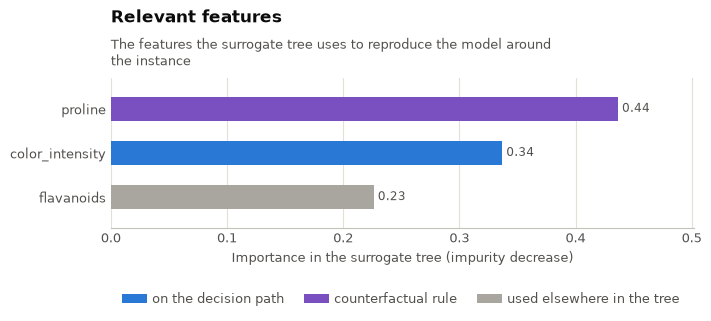

In [6]:
import nife.plotting

original = nife.plotting.COLORS["counterfactual"]
nife.plotting.COLORS["counterfactual"] = "#7a4fbf"
explanation.plot_importances()
nife.plotting.COLORS["counterfactual"] = original

## New plots

A new plot is a method named `plot_<kind>` of an explanation class; `plot("<kind>")` and `plot_kinds()` find it, and subclasses inherit it. [extending.ipynb](extending.ipynb#A-new-plot) shows how to write one with the helpers of `nife.plotting`, so that it looks like the others.